# Часть 0. Подготовка

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mnist import load_mnist

# Загружаем данные
train, validation, test = load_mnist()

# Извлекаем картинки и метки
X_train_full, y_train_full = train
X_val, y_val = validation
X_test, y_test = test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Extracting MNIST-data\train-images-idx3-ubyte.gz
Extracting MNIST-data\train-labels-idx1-ubyte.gz
Extracting MNIST-data\t10k-images-idx3-ubyte.gz
Extracting MNIST-data\t10k-labels-idx1-ubyte.gz
Размер обучающей выборки: (55000, 28, 28, 1)
Размер валидационной выборки: (5000, 28, 28, 1)
Размер тестовой выборки: (10000, 28, 28, 1)


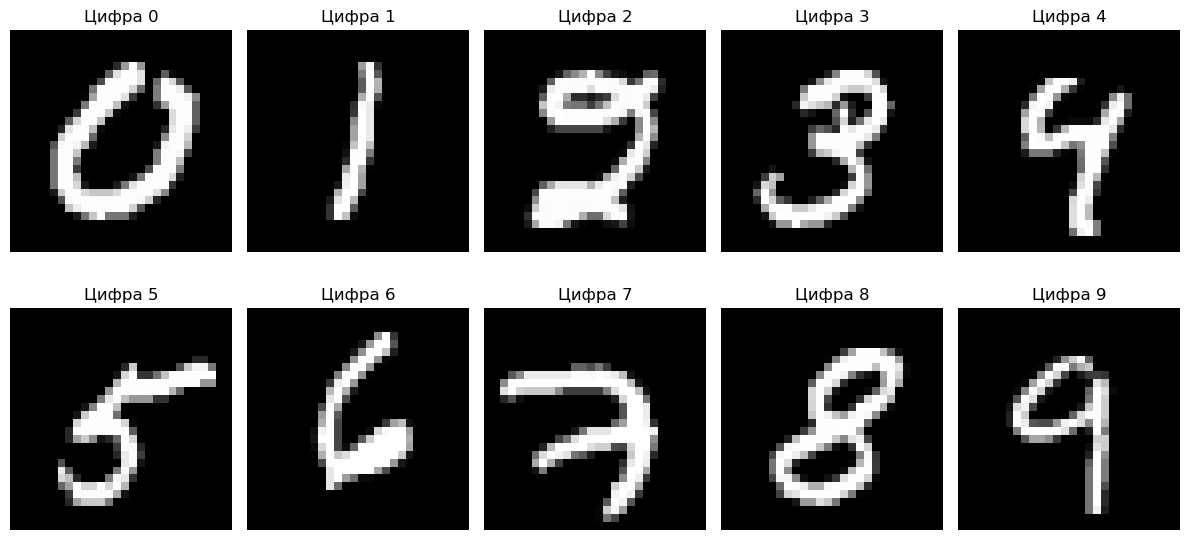

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i in range(10):
    index = np.where(y_train_full == i)[0][0]
    img = X_train_full[index]
    axes.flat[i].imshow(img.reshape(28, 28), cmap='gray')
    axes.flat[i].set_title(f"Цифра {i}")
    axes.flat[i].axis('off')

plt.tight_layout()
plt.show()

In [3]:
# Объединяем train и validation
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)

# Преобразуем форму: (n, 28, 28, 1) -> (n, 784)
X = X.reshape(X.shape[0], -1)

# Нормализуем
X = X.astype(np.float32) / 255.0

print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")

Форма X: (60000, 784)
Форма y: (60000,)
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]


# Часть 1. Метод главных компонент (PCA)

Реализуйте класс `my_PCA`, аналогичный `sklearn.decomposition.PCA`.

```python
class my_PCA:
    def __init__(self, n_components=None):
        """
        Parameters
        ----------
        n_components : int or None
            Количество главных компонент. Если None, сохраняются все.
        """
        self.n_components = n_components
        self.components_ = None       # главные компоненты (собственные векторы)
        self.explained_variance_ = None  # собственные значения
        self.mean_ = None             # среднее по каждому признаку
        
    def fit(self, X):
        """
        Обучает PCA на данных X.
        
        Шаги:
        1. Центрировать данные
        2. Вычислить матрицу ковариации (или использовать SVD)
        3. Найти собственные векторы и значения
        4. Отсортировать по убыванию собственных значений
        5. Сохранить первые n_components компонент
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        """
        # TODO: Реализуйте обучение
        
        # Шаг 1: Центрирование
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_
        
        # Шаг 2-3: Используйте np.linalg.svd (рекомендуется!) или np.linalg.eig
        # SVD: X_centered = U @ S @ Vt
        # Собственные значения ковариации = S^2 / (n-1)
        # Собственные векторы = Vt.T
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
        
        # TODO: Сохраните собственные значения и векторы
        # explained_variance = S^2 / (n - 1)
        # components = Vt
        
        # TODO: Отсортируйте (SVD уже возвращает в порядке убывания)
        # TODO: Если n_components задано, оставьте только первые n_components
        
        return self
    
    def transform(self, X):
        """
        Преобразует данные в координаты главных компонент.
        
        Y = (X - mean) @ components[:n_components].T
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        Y : np.array, shape (n_samples, n_components)
        """
        # TODO: Реализуйте преобразование
        pass
    
    def fit_transform(self, X):
        """
        Обучает и сразу преобразует.
        """
        return self.fit(X).transform(X)
```

**Подсказка:** Для реализации рекомендуется использовать **SVD** (сингулярное разложение), а не `np.linalg.eig`. Это численно устойчивее и работает быстрее.

### Задание 1.2: Проверка реализации

Убедитесь, что ваш PCA работает правильно, сравнив его с `sklearn.decomposition.PCA`:

```python
from sklearn.decomposition import PCA

# Обучите оба PCA на одних данных
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

# Проверьте, что результаты близки (с точностью до знака)
print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")

# Проверка: результат должен совпадать с точностью до знака
print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")
```

**Вопрос:** Совпадают ли собственные значения? Если да, то ваша реализация верна.

### Задание 1.3: Визуализация дисперсии

Постройте два графика:
1. **График собственных значений** — покажет, как убывают дисперсии по компонентам
2. **Кумулятивная сумма дисперсии** (нормированная на полную сумму) — покажет, сколько компонент нужно для объяснения X% дисперсии

```python
# TODO: Обучите PCA со всеми компонентами
pca_full = my_PCA()
pca_full.fit(X)

# TODO: Постройте графики
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: собственные значения
# axes[0].plot(...)
# axes[0].set_xlabel('Номер компоненты')
# axes[0].set_ylabel('Собственное значение (дисперсия)')
# axes[0].set_title('Спектр собственных значений')

# График 2: кумулятивная дисперсия
# cumulative = np.cumsum(pca_full.explained_variance_)
# cumulative /= cumulative[-1]
# axes[1].plot(...)
# axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
# axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% дисперсии')
# axes[1].set_xlabel('Число компонент')
# axes[1].set_ylabel('Доля объяснённой дисперсии')
# axes[1].set_title('Кумулятивная дисперсия')
# axes[1].legend()

plt.tight_layout()
plt.show()
```

**Вопросы для ответа текстом:**

1. Какую долю дисперсии покрывают первые **15 главных компонент**?
2. Сколько компонент нужно, чтобы объяснить **95%** дисперсии?
3. Как связаны собственные числа и дисперсия данных? Объясните своими словами.

### Задание 1.4: Визуализация данных в первых двух компонентах

Спроецируйте данные на первые две главные компоненты и постройте scatter plot, где разные цифры обозначены разными цветами.

```python
# TODO: Преобразуйте данные в первые 2 компоненты
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

# TODO: Постройте scatter plot
plt.figure(figsize=(10, 8))
# for digit in range(10):
#     mask = (y == digit)
#     plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.5, s=10)
# plt.legend()
# plt.xlabel('Первая главная компонента')
# plt.ylabel('Вторая главная компонента')
# plt.title('Данные MNIST в первых двух главных компонентах')
# plt.show()
```

**Вопрос:** Видны ли классы (цифры) раздельно в первых двух компонентах? Какие цифры визуально группируются вместе? Почему?

---


Реализовали PCA через SVD: отцентрировали данные (вычли среднее по каждому пикселю, чтобы оси шли через центр облака, а не через начало координат), разложили центрированную матрицу через np.linalg.svd и получили собственные значения, а сами компоненты — как строки Vt. Обрезка до n_components берёт первые k строк, потому что SVD уже отсортировал их по убыванию дисперсии. В transform мы просто центрируем новые данные и умножаем на components_.T, получая координаты в новом базисе. 

In [4]:
class my_PCA:
    def __init__(self, n_components=None):
        """
        Parameters
        ----------
        n_components : int or None
            Количество главных компонент. Если None, сохраняются все.
        """
        self.n_components = n_components
        self.components_ = None       # главные компоненты (собственные векторы)
        self.explained_variance_ = None  # собственные значения
        self.mean_ = None             # среднее по каждому признаку
        
    def fit(self, X):
        """
        Обучает PCA на данных X.
        
        Шаги:
        1. Центрировать данные
        2. Вычислить матрицу ковариации (или использовать SVD)
        3. Найти собственные векторы и значения
        4. Отсортировать по убыванию собственных значений
        5. Сохранить первые n_components компонент
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        """
        # Центрирование
        self.mean_ = np.mean(X, axis=0)        #Считаем среднее по каждому признаку
        X_centered = X - self.mean_
        
        # SVD: X_centered = U @ S @ Vt
        # Собственные значения ковариации = S^2 / (n-1)
        # Собственные векторы = Vt.T
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
        
        # Сохраните собственные значения и векторы
        explained_variance = S**2 / (X.shape[0] - 1)
        components = Vt
        
        # Если n_components задано, оставьте только первые n_components
        if self.n_components is not None:
            explained_variance = explained_variance[:self.n_components]
            components = components[:self.n_components]

        self.explained_variance_ = explained_variance
        self.components_ = components
        return self
    
    def transform(self, X):
        """
        Преобразует данные в координаты главных компонент.
        
        Y = (X - mean) @ components[:n_components].T
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        Y : np.array, shape (n_samples, n_components)
        """
        X_centered = X - self.mean_
        return X_centered @ self.components_.T
    
    def fit_transform(self, X):
        """
        Обучает и сразу преобразует.
        """
        return self.fit(X).transform(X)

In [5]:
from sklearn.decomposition import PCA

# Обучите оба PCA на одних данных
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

# Проверьте, что результаты близки (с точностью до знака)
print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")

# Проверка: результат должен совпадать с точностью до знака
print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")

Сумма собственных значений (my): 45.48
Сумма собственных значений (sklearn): 45.48
Форма Y_my: (1000, 50)
Форма Y_sk: (1000, 50)


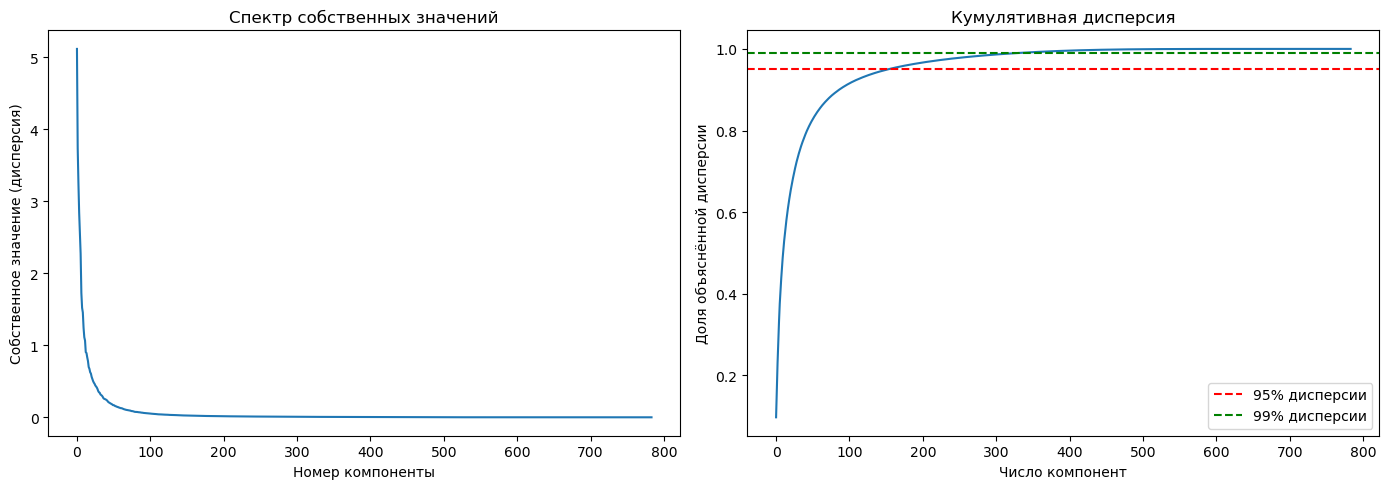

In [6]:
# Обучаем PCA со всеми компонентами
pca_full = my_PCA()
pca_full.fit(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: собственные значения
axes[0].plot(pca_full.explained_variance_)
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Собственное значение (дисперсия)')
axes[0].set_title('Спектр собственных значений')

# График 2: кумулятивная дисперсия
cumulative = np.cumsum(pca_full.explained_variance_)
cumulative /= cumulative[-1]   # нормируем: в конце должно быть ровно 1.0
axes[1].plot(cumulative)

axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% дисперсии')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Доля объяснённой дисперсии')
axes[1].set_title('Кумулятивная дисперсия')
axes[1].legend()

plt.tight_layout()
plt.show()

In [7]:
n_95 = np.argmax(cumulative >= 0.95) + 1
n_99 = np.argmax(cumulative >= 0.99) + 1

print(f"Первые 15 компонент покрывают: {cumulative[14] * 100:.2f}% дисперсии")
print(f"Для 95% дисперсии нужно компонент: {n_95}")
print(f"Для 99% дисперсии нужно компонент: {n_99}")

Первые 15 компонент покрывают: 57.93% дисперсии
Для 95% дисперсии нужно компонент: 154
Для 99% дисперсии нужно компонент: 331


Связь собственных чисел и дисперсии: собственное число λᵢ показывает, насколько сильно данные разбросаны вдоль i-й главной компоненты. Чем больше λ, тем больше информации несёт эта ось. Сумма всех λ равна полной дисперсии данных, поэтому нормированная кумулятивная сумма и даёт «долю объяснённой информации».

Далее спроецировали все 60 000 картинок на первые две главные компоненты и увидели, что классы в 2D почти не разделяются — большинство цифр образуют одно плотное перемешанное облако. Это прямое следствие того, что две компоненты несут лишь четверть всей дисперсии, а форма цифр — это многомерная структура, которую двумя осями не описать. Главный вывод: двух компонент для классификации недостаточно, но они хорошо работают для визуализации и понимания общей структуры данных.



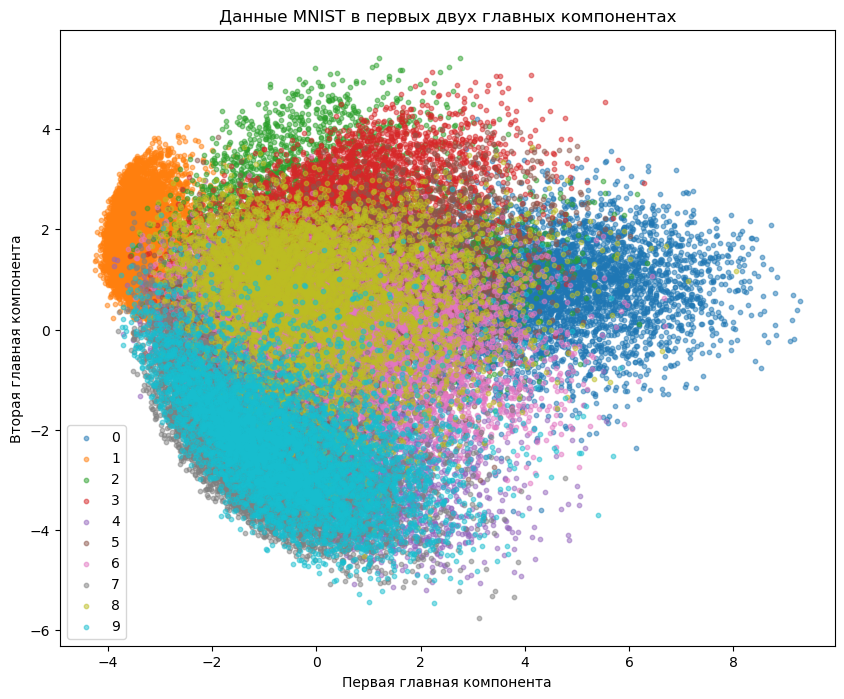

In [8]:
# TПреобразовываем данные в первые 2 компоненты
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

# scatter plot
plt.figure(figsize=(10, 8))
for digit in range(10):
    mask = (y == digit)
    plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.5, s=10)

plt.legend()
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Данные MNIST в первых двух главных компонентах')
plt.show()

# Часть 2. Метод k-ближайших соседей (kNN)

### Теория: Как работает kNN?

**Идея:** Объект относится к тому классу, к которому принадлежит **большинство** из его $k$ ближайших соседей в обучающей выборке.

**Алгоритм предсказания для объекта $x$:**
1. Найти расстояния от $x$ до всех объектов обучающей выборки
2. Выбрать $k$ объектов с наименьшими расстояниями
3. Найти самый частый класс среди этих $k$ объектов
4. Вернуть этот класс как предсказание

**Метрика расстояния:** Обычно используется **евклидово расстояние**:
$$ d(x, x') = \sqrt{\sum_{i=1}^{d} (x_i - x'_i)^2} $$

### Задание 2.1: Реализация my_kNN

```python
class my_kNN:
    def __init__(self, n_neighbors=5):
        """
        Parameters
        ----------
        n_neighbors : int
            Число соседей
        """
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None
    
    def fit(self, X, y):
        """
        Запоминает обучающую выборку.
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        y : np.array, shape (n_samples,)
        """
        # TODO: Сохраните X и y
        pass
    
    def predict(self, X):
        """
        Предсказывает классы для объектов X.
        
        Для каждого объекта x из X:
        1. Вычислите расстояние до всех объектов X_train
        2. Найдите k ближайших
        3. Верните самый частый класс
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        y_pred : np.array, shape (n_samples,)
        """
        # TODO: Реализуйте предсказание
        # Подсказка: используйте np.argsort для поиска k ближайших
        # Для подсчёта самого частого класса используйте np.bincount или scipy.stats.mode
        pass
```

**Подсказка по эффективности:** Если вычислять расстояния в цикле по объектам, это может быть медленно. Используйте матричные операции:
- Для вычисления матрицы расстояний можно применить формулу: $\|x - x'\|^2 = \|x\|^2 + \|x'\|^2 - 2 \langle x, x' \rangle$

### Задание 2.2: Проверка реализации

Убедитесь, что ваш kNN работает правильно:

```python
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Обучите свой kNN
my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)

accuracy_my = accuracy_score(y_test, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}")
```

**Вопрос:** Если точность около **10%**, значит алгоритм работает как случайный (10 классов). Если точность **>90%**, всё хорошо. Какая у вас точность?

### Задание 2.3: Сравнение с sklearn

Сравните ваш kNN с `sklearn.neighbors.KNeighborsClassifier`:

```python
from sklearn.neighbors import KNeighborsClassifier

# Обучите sklearn kNN
sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")
```

**Вопрос:** Совпадают ли результаты? Если разница большая, проверьте реализацию.

### Задание 2.4: Эксперимент с числом соседей

Исследуйте, как зависит точность от числа соседей $k$. Попробуйте $k \in \{1, 3, 5, 7, 10, 15, 20, 30\}$.

```python
# TODO: Постройте график зависимости accuracy от k
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

for k in k_values:
    # TODO: Обучите kNN, посчитайте accuracy
    pass

# TODO: Постройте график
plt.figure(figsize=(8, 5))
# plt.plot(k_values, accuracies, 'o-')
# plt.xlabel('Число соседей k')
# plt.ylabel('Точность')
# plt.title('Зависимость точности kNN от числа соседей')
# plt.grid(True)
# plt.show()
```

**Вопрос:** При каком $k$ точность максимальна? Почему при малых $k$ точность ниже? А при слишком больших?

---


Мы реализовали kNN: fit просто запоминает выборку, а predict для каждого тестового объекта считает расстояние до всех обучающих, находит k ближайших и возвращает самый частый класс среди них. Расстояния считаем матрично через формулу ||x−x'||² = ||x||² + ||x'||² − 2⟨x,x'⟩. Для голосования используем np.bincount с minlength=10, чтобы индекс совпадал с номером цифры.

In [9]:
class my_kNN:
    def __init__(self, n_neighbors=5):
        """
        Parameters
        ----------
        n_neighbors : int
            Число соседей
        """
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None
    
    def fit(self, X, y):
        """
        Запоминает обучающую выборку.
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        y : np.array, shape (n_samples,)
        """
        self.X_train = X
        self.y_train = y
        return self
    
    def predict(self, X):
        """
        Предсказывает классы для объектов X.
        
        Для каждого объекта x из X:
        1. Вычислите расстояние до всех объектов X_train
        2. Найдите k ближайших
        3. Верните самый частый класс
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        y_pred : np.array, shape (n_samples,)
        """
        #1. Вычислите расстояние до всех объектов X_train
        X2 = np.sum(X ** 2, axis=1, keepdims=True)   # keepdims=True нужен для правильного broadcasting.
        T2 = np.sum(self.X_train ** 2, axis=1, keepdims=True).T   
        dists = X2 + T2 - 2 * X @ self.X_train.T 
        
        #2. Найдите k ближайших
        idx = np.argsort(dists, axis=1)[:, :self.n_neighbors]        ## argsort возвращает индексы, упорядоченные по возрастанию расстоянию

        #3. Верните самый частый класс
        y_pred = np.zeros(X.shape[0], dtype=self.y_train.dtype)
        for i in range(X.shape[0]):
            labels = self.y_train[idx[i]]
            #bincount(labels, minlength=10).argmax() — самый частый класс, minlength=10 гарантирует, что индекс совпадает с номером цифры.
            y_pred[i] = np.bincount(labels, minlength=10).argmax()
        return y_pred
        

In [10]:
# Проверка реализации
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Обучите свой kNN
my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)

accuracy_my = accuracy_score(y_test, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}")

Точность my_kNN: 0.9668


**Ответ на вопрос**: Точность моего kNN = 0.9668, что соответствует ожидаемому уровню для MNIST при k=5. Это сильно выше 10% (случайное угадывание среди 10 классов), значит алгоритм действительно работает и классифицирует цифры, а не угадывает. Небольшое расхождение с идеалом объясняется тем, что некоторые цифры визуально похожи (4/9, 3/5/8), и часть объектов неизбежно классифицируется неверно.

In [11]:
# Сравнение с sklearn
from sklearn.neighbors import KNeighborsClassifier

# Обучите sklearn kNN
sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")

Точность sklearn kNN: 0.9668
Разница: 0.0000


**Ответ на вопрос:** Результаты совпали — разница 0.0000. Это подтверждает, что наша реализация математически эквивалентна sklearn.

Проверили, как число ближайших соседей влияет на точность классификации. Наибольшая точность получена при (k=3) и составляет 0.969. При увеличении (k) точность постепенно снижается.

k=1: accuracy=0.9680
k=3: accuracy=0.9690
k=5: accuracy=0.9668
k=7: accuracy=0.9649
k=10: accuracy=0.9628
k=15: accuracy=0.9594
k=20: accuracy=0.9564
k=30: accuracy=0.9519


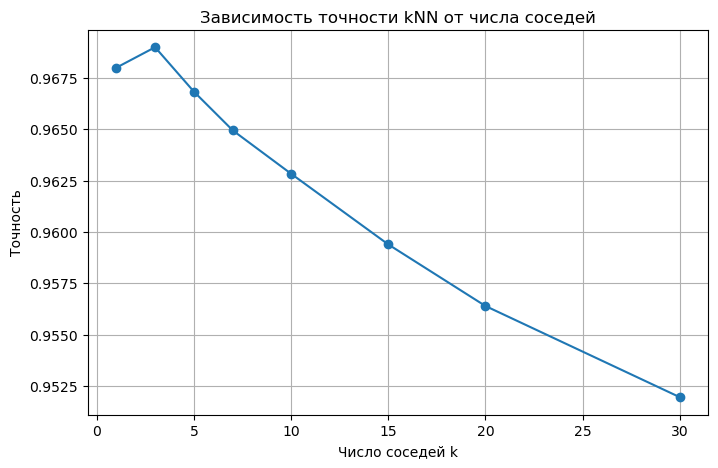

In [12]:
# Постройте график зависимости accuracy от k
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

for k in k_values:
    knn = my_kNN(n_neighbors=k)
    knn.fit(X_train, y_train)
    pred = knn.predict(X_test)
    acc = accuracy_score(y_test, pred)
    accuracies.append(acc)
    print(f"k={k}: accuracy={acc:.4f}")

# Постройте график
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, 'o-')
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа соседей')
plt.grid(True)
plt.show()

# Часть 3. PCA + kNN: Понижение размерности для классификации

### Теория: Зачем комбинировать PCA и kNN?

**Проблемы kNN на полных данных:**
- **Вычислительная сложность:** расстояние считается по 784 признакам
- **"Проклятие размерности":** в высоких размерностях расстояния между точками становятся похожими
- **Шум:** неинформативные признаки мешают

**Решение:** Сначала уменьшить размерность с помощью PCA, потом обучить kNN.

**Вопрос для размышления:** Как вы думаете, улучшится ли качество? А скорость работы?

### Задание 3.1: Применение PCA перед kNN

Обучите последовательно: PCA (с разным числом компонент) → kNN.

```python
# TODO: Переберите число компонент от 1 до 100
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []

for n_comp in n_components_list:
    # TODO: 
    # 1. Примените PCA к X_train и X_test
    # 2. Обучите kNN на преобразованных данных
    # 3. Посчитайте accuracy
    pass

# TODO: Постройте график
plt.figure(figsize=(10, 6))
# plt.plot(n_components_list, accuracies_pca, 'o-')
# plt.axhline(y=accuracy_my, color='r', linestyle='--', label=f'kNN на всех признаках ({accuracy_my:.3f})')
# plt.xlabel('Число главных компонент')
# plt.ylabel('Точность')
# plt.title('Зависимость точности kNN от числа компонент PCA')
# plt.legend()
# plt.grid(True)
# plt.show()
```

**Вопросы:**
1. При каком числе компонент точность максимальна?
2. Удалось ли превзойти точность kNN на всех 784 признаках?
3. Что происходит при слишком малом числе компонент? Почему?

### Задание 3.2: Исследование времени работы

Замерьте время работы kNN с разным числом компонент.

```python
import time

# TODO: Замерьте время для разных n_components
times = []
for n_comp in n_components_list:
    start = time.time()
    # ... обучение и предсказание ...
    elapsed = time.time() - start
    times.append(elapsed)

# TODO: Постройте график времени
plt.figure(figsize=(10, 6))
# plt.plot(n_components_list, times, 'o-')
# plt.xlabel('Число компонент')
# plt.ylabel('Время (сек)')
# plt.title('Время работы kNN в зависимости от числа компонент')
# plt.grid(True)
# plt.show()
```

**Вопрос:** Как изменяется время работы при уменьшении размерности? Объясните.

### Задание 3.3: Финальный эксперимент — сетка параметров

Проведите **совместный** перебор параметров:
- Число компонент PCA: $[5, 10, 15, 20, 30, 50, 100]$
- Число соседей $k$: $[1, 3, 5, 7, 10]$

Для каждой комбинации посчитайте точность. Постройте **heatmap** (тепловую карту) с точностью.

```python
# TODO: Переберите все комбинации
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    # Примените PCA
    # ...
    for j, k in enumerate(k_grid):
        # Обучите kNN
        # ...
        pass

# TODO: Постройте heatmap
import seaborn as sns
plt.figure(figsize=(10, 6))
# sns.heatmap(accuracy_matrix, annot=True, fmt='.3f',
#             xticklabels=k_grid, yticklabels=n_components_grid,
#             cmap='viridis')
# plt.xlabel('Число соседей k')
# plt.ylabel('Число компонент PCA')
# plt.title('Точность классификации MNIST')
# plt.show()
```

**Вопросы:**
1. Какая комбинация параметров даёт **наилучшую** точность?
2. Какая — **наихудшую**?
3. Есть ли комбинации, где точность **выше**, чем у kNN на полных данных? Что это говорит о PCA?

---


Исследовали зависимость точности классификации от числа главных компонент. Максимальная точность получена при 30 компонентах и составляет 0.934. Это выше результата базовой модели на той же подвыборке.

n_components=1: accuracy=0.2570
n_components=2: accuracy=0.4285
n_components=5: accuracy=0.7045
n_components=10: accuracy=0.8730
n_components=15: accuracy=0.9155
n_components=20: accuracy=0.9330
n_components=30: accuracy=0.9335
n_components=50: accuracy=0.9330
n_components=75: accuracy=0.9290
n_components=100: accuracy=0.9240
n_components=200: accuracy=0.9215
n_components=300: accuracy=0.9195
n_components=500: accuracy=0.9190
n_components=784: accuracy=0.9190

Baseline kNN без PCA (та же подвыборка): 0.9190


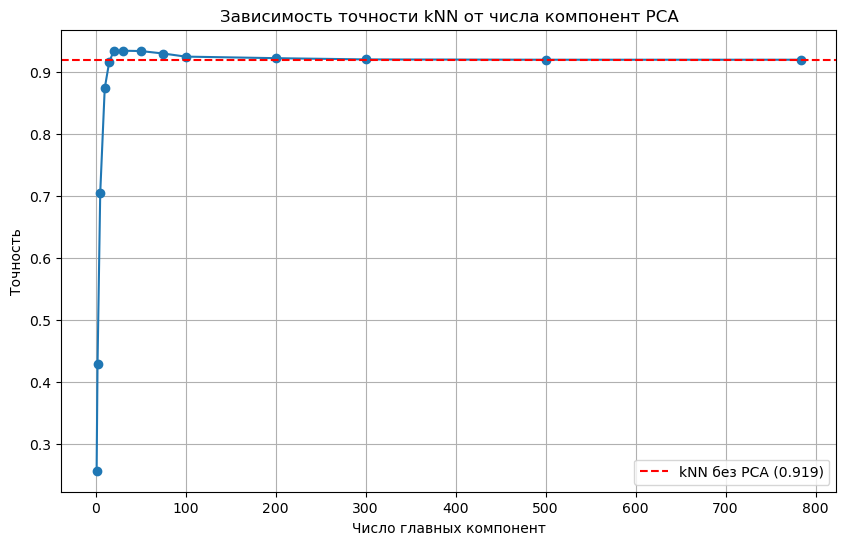

In [14]:
# уменьшаем выборку, чтобы было быстрее
X_train_small = X_train[:5000]
y_train_small = y_train[:5000]
X_test_small  = X_test[:2000]
y_test_small  = y_test[:2000]

# Переберите число компонент от 1 до 100
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []

for n_comp in n_components_list:
    # 1. Примените PCA к X_train и X_test
    pca = my_PCA(n_components=n_comp)
    X_train_p = pca.fit_transform(X_train_small)   
    X_test_p = pca.transform(X_test_small)  
    
    # 2. Обучите kNN на преобразованных данных
    knn = my_kNN(n_neighbors=5)
    knn.fit(X_train_p, y_train_small)
    pred = knn.predict(X_test_p)
    
    # 3. Посчитайте accuracy
    acc = accuracy_score(y_test_small, pred)
    accuracies_pca.append(acc)
    print(f"n_components={n_comp}: accuracy={acc:.4f}")

# Baseline: kNN без PCA на той же подвыборке 
knn_base = my_kNN(n_neighbors=5)
knn_base.fit(X_train_small, y_train_small)
acc_base = accuracy_score(y_test_small, knn_base.predict(X_test_small))
print(f"\nBaseline kNN без PCA (та же подвыборка): {acc_base:.4f}")

# Постройте график
plt.figure(figsize=(10, 6))
plt.plot(n_components_list, accuracies_pca, 'o-')
plt.axhline(y=acc_base, color='r', linestyle='--', label=f'kNN без PCA ({acc_base:.3f})')
plt.xlabel('Число главных компонент')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа компонент PCA')
plt.legend()
plt.grid(True)
plt.show()

**Ответы на вопросы текстом**
1. Максимум — 30 компонент (0.9335), плато с 15 (0.9155). Дальше точность медленно падает.

2. Да, превзошли baseline: 0.9335 против 0.9190. 

3. При 1–5 компонентах точность резко падает — мало информации о форме. Оптимум при 30, а избыток компонент вредит: при 784 шум возвращается и точность падает до baseline.

Сравнили время выполнения алгоритма при разном числе главных компонент. Измерения включают преобразование PCA и классификацию kNN. Время зависит от числа компонент, но для надёжного сравнения нужны повторные замеры.

n_components=1: time=2.311s
n_components=2: time=2.424s
n_components=5: time=6.356s
n_components=10: time=6.944s
n_components=15: time=6.374s
n_components=20: time=6.154s
n_components=30: time=6.265s
n_components=50: time=4.573s
n_components=75: time=6.693s
n_components=100: time=6.737s
n_components=200: time=6.806s
n_components=300: time=6.611s
n_components=500: time=6.644s
n_components=784: time=9.684s


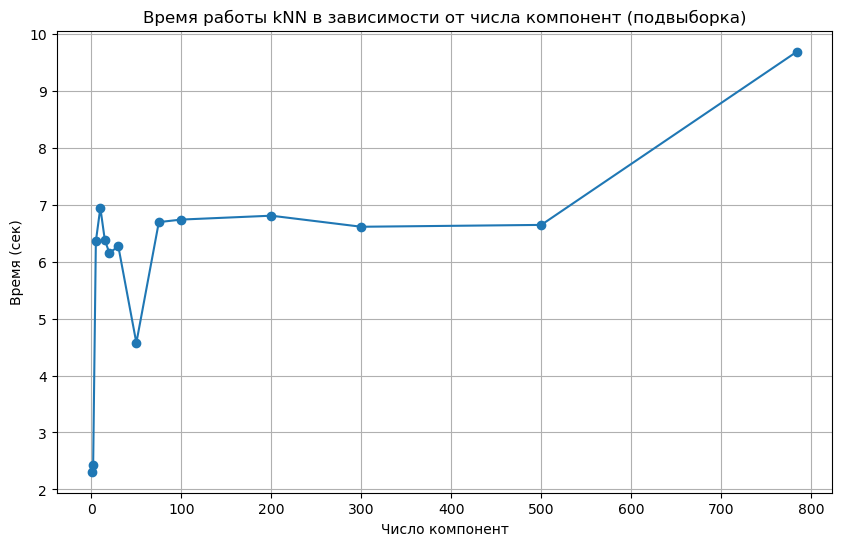

In [15]:
import time

# Замерьте время для разных n_components
times = []
for n_comp in n_components_list:
    start = time.time()
    
    # ... обучение и предсказание ...
    pca = my_PCA(n_components=n_comp)
    X_train_p = pca.fit_transform(X_train_small)   
    X_test_p = pca.transform(X_test_small)  

    knn = my_kNN(n_neighbors=5)
    knn.fit(X_train_p, y_train_small)
    pred = knn.predict(X_test_p)
    
    elapsed = time.time() - start
    times.append(elapsed)
    print(f"n_components={n_comp}: time={elapsed:.3f}s")

# Постройте график времени
plt.figure(figsize=(10, 6))
plt.plot(n_components_list, times, 'o-')
plt.xlabel('Число компонент')
plt.ylabel('Время (сек)')
plt.title('Время работы kNN в зависимости от числа компонент (подвыборка)')
plt.grid(True)
plt.show()

Построили Heatmap точности для разных сочетаний числа главных компонент и количества соседей. Это позволяет наглядно сравнить результаты и определить наиболее удачные параметры модели.

Heatmap показал, что лучший результат достигается при 30 компонентах и \(k=3\) — около 0.942. Наихудший результат получен при 5 компонентах и \(k=1\) — около 0.651.

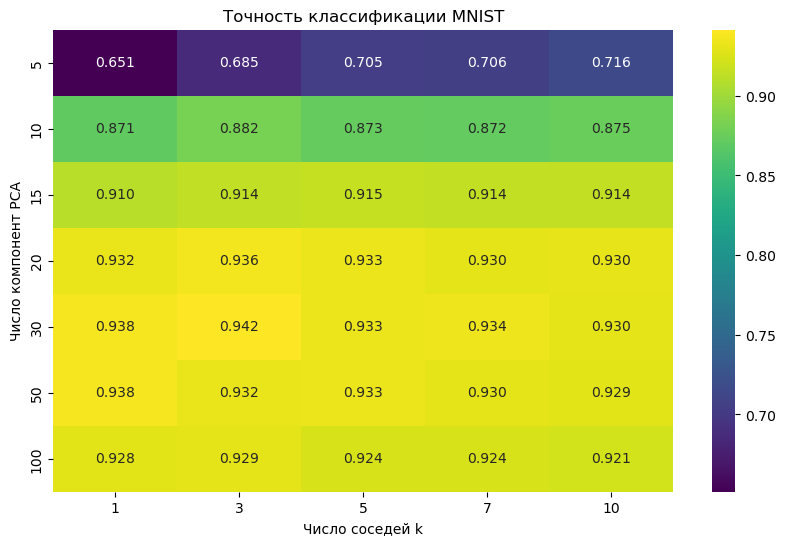

In [18]:
# Переберите все комбинации
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    # Примените PCA
    pca = my_PCA(n_components=n_comp)
    X_train_p = pca.fit_transform(X_train_small)
    X_test_p = pca.transform(X_test_small)
    
    for j, k in enumerate(k_grid):
        # Обучите kNN
        knn = my_kNN(n_neighbors=k)
        knn.fit(X_train_p, y_train_small)
        pred = knn.predict(X_test_p)
        accuracy_matrix[i, j] = accuracy_score(y_test_small, pred)

# Постройте heatmap
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.heatmap(accuracy_matrix, annot=True, fmt='.3f',
            xticklabels=k_grid, yticklabels=n_components_grid,
            cmap='viridis')
plt.xlabel('Число соседей k')
plt.ylabel('Число компонент PCA')
plt.title('Точность классификации MNIST')
plt.show()

**Ответы на вопросы**

1. Лучшая: n_comp=30, k=3 — 0.942.

2. Худшая: n_comp=5, k=1 — 0.651 (мало информации + размытая граница).

3. Да, PCA помогает: многие комбинации дают 0.93–0.94 против baseline 0.919. Это значит, что отбрасывание шумовых компонент улучшает kNN, а не вредит.

# Часть 4. Выводы 

**1. Что такое PCA? Как он работает? Зачем нужен?**  
PCA — метод уменьшения размерности данных, который преобразует исходные признаки в главные компоненты, сохраняющие наибольшую дисперсию. Он позволяет сократить количество признаков и ускорить обработку данных.

**2. Что такое kNN? Как работает? Какие у него есть плюсы и минусы?**  
kNN классифицирует объект по классам его \(k\) ближайших соседей. Его плюсы — простота и хорошая точность, минусы — медленное предсказание на больших данных и чувствительность к выбору \(k\).

**3. Как PCA влияет на качество kNN? Что лучше — использовать все признаки или уменьшить размерность?**  
В эксперименте PCA повысил точность: при 30 компонентах она составила 0,9335 против 0,9190 без PCA на той же подвыборке. Уменьшение размерности может ускорить работу и улучшить качество, если сохраняется достаточно информации.

**4. Какова оптимальная размерность для MNIST? Почему?**  
В проведённом эксперименте лучший результат получен при 30 компонентах: точность составила 0,9335. При меньшем числе компонент теряется важная информация, а при увеличении их количества качество постепенно снижается.

**5. Что было самым сложным при выполнении работы?**  
Самым сложным было реализовать PCA и kNN самостоятельно, правильно вычислить расстояния между объектами и проверить корректность результатов.

**6. Что было самым интересным?**  
Самым интересным было исследовать, как количество главных компонент и соседей влияет на точность классификации рукописных цифр, и сравнить результаты с использованием PCA и без него.
